In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

In [2]:
files = [
    "data/Unfallorte2020_LinRef.csv",
    "data/Unfallorte_2021_LinRef.txt",
    "data/Unfallorte2022_LinRef.csv",
    "data/Unfallorte2023_LinRef.csv",
    "data/Unfallorte2024_LinRef.csv",
    "data/Unfallorte_2025_LR_BasisDLM.csv",
]

frames = []
for f in files:
    d = pd.read_csv(f, sep=";", decimal=",")
    d = d.rename(columns={"IstStrassenzustand": "STRZUSTAND"})   # ab 2021 anders benannt
    d = d.drop(columns=["OBJECTID", "OID_", "UIDENTSTLAE", "PLST"], errors="ignore")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)

/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_87079/287246640.py:12: DtypeWarning: Columns (23: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_87079/287246640.py:12: DtypeWarning: Columns (1: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")
/var/folders/l_/gx9nbvqs3s181hk13j3hthlw0000gp/T/ipykernel_87079/287246640.py:12: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f, sep=";", decimal=",")


In [3]:
print(df.shape) 
print(df.isna().sum().sum())                     
print(df["UJAHR"].value_counts().sort_index()) 
print(df.groupby("UJAHR")["ULAND"].nunique())    
print(df.groupby("UJAHR")["UMONAT"].nunique())    

(1543886, 23)
0
UJAHR
2020    237994
2021    238826
2022    256492
2023    269048
2024    268519
2025    273007
Name: count, dtype: int64
UJAHR
2020    16
2021    16
2022    16
2023    16
2024    16
2025    16
Name: ULAND, dtype: int64
UJAHR
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
Name: UMONAT, dtype: int64


In [4]:
print(df.dtypes)

ULAND            int64
UREGBEZ          int64
UKREIS           int64
UGEMEINDE        int64
UJAHR            int64
UMONAT           int64
USTUNDE          int64
UWOCHENTAG       int64
UKATEGORIE       int64
UART             int64
UTYP1            int64
ULICHTVERH       int64
IstRad           int64
IstPKW           int64
IstFuss          int64
IstKrad          int64
IstGkfz          int64
IstSonstige      int64
LINREFX        float64
LINREFY        float64
XGCSWGS84      float64
YGCSWGS84      float64
STRZUSTAND       int64
dtype: object


In [5]:
df_rad = df[df["IstRad"] == 1].copy()
print(len(df_rad))

500799


1. Zeitliche Entwicklung

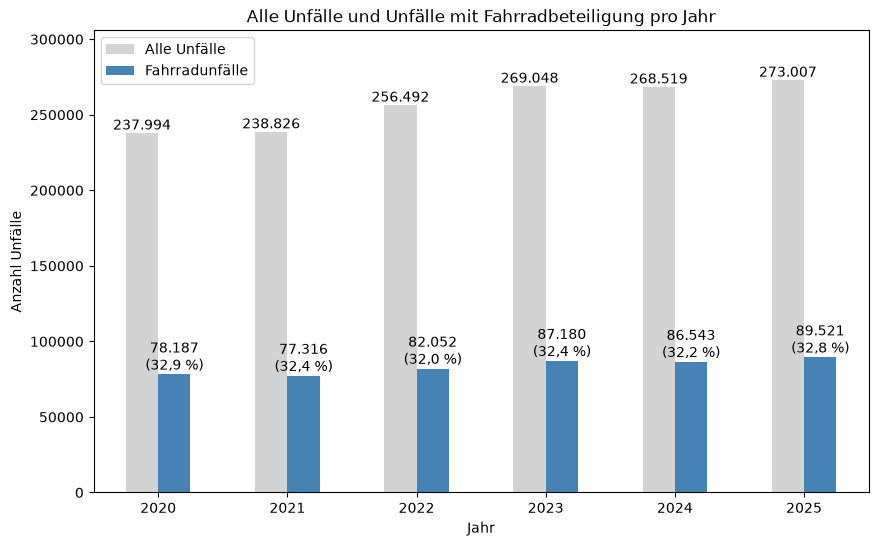

In [6]:
#  1.1 Entwicklung der Fahrradunfälle pro Jahr

alle_year = df.groupby("UJAHR").size()
rad_year = df_rad.groupby("UJAHR").size()
anteil = (rad_year / alle_year * 100).round(1)

vergleich = pd.DataFrame({
    "Alle Unfälle": alle_year,
    "Fahrradunfälle": rad_year,
})

ax = vergleich.plot(kind="bar", figsize=(10, 6), color=["lightgray", "steelblue"])


ax.bar_label(ax.containers[0], labels=[f"{v:,}".replace(",", ".") for v in alle_year])
ax.bar_label(
    ax.containers[1],
    labels=[f"{v:,}".replace(",", ".") + f"\n({str(a).replace('.', ',')} %)"
            for v, a in zip(rad_year, anteil)]
)

plt.title("Alle Unfälle und Unfälle mit Fahrradbeteiligung pro Jahr")
plt.xlabel("Jahr")
plt.ylabel("Anzahl Unfälle")
plt.xticks(rotation=0)
plt.ylim(0, alle_year.max() * 1.12)
plt.legend();

Zwischen 2020 und 2025 ist die Zahl der Unfälle mit Fahrradbeteiligung von 78.187 auf 89.521 gestiegen, das entspricht einem Plus von rund 14,5 %. Den niedrigsten Wert gab es 2021 (77.316), den höchsten 2025 (89.521). Die Entwicklung verlief nicht gleichmäßig: Auf einen leichten Rückgang 2021 (−1,1 %) folgten zwei Anstiege 2022 und 2023 (jeweils rund +6 %), danach ein minimaler Rückgang 2024 (−0,7 %) und erneut ein Anstieg 2025 (+3,4 %).

Der Anteil der Fahrradunfälle an allen Unfällen mit Personenschaden blieb in allen Jahren nahezu konstant bei 32,0 bis 32,9 %. Die Fahrradunfälle sind also nicht überproportional gewachsen, sondern im Gleichschritt mit der Gesamtzahl der Unfälle (von 237.994 auf 273.007, ebenfalls rund +15 %). Die Daten enthalten keine Angaben zur tatsächlichen Fahrradnutzung, daher lässt sich aus der Entwicklung nicht ableiten, ob Radfahren riskanter geworden ist.

UJAHR   2020   2021   2022   2023   2024   2025
UMONAT                                         
1       4274   2337   3455   3963   3293   4067
2       3642   2975   3408   3927   4055   3436
3       3670   4526   5940   4868   5617   6064
4       5932   4996   5475   5251   7042   8033
5       7500   6417  10184  10015  10163  10752
6       9204  11266   9914  12537  10194  11035
7       9598   9653   9390  10139  10560  10567
8       9141   8191   9380   9050  10487  10339
9       9978  10085   8124  11388   9063   8975
10      6460   7374   7553   7396   7066   6435
11      5237   5349   5890   5351   5349   5477
12      3551   4147   3339   3295   3654   4341
UMONAT
6    64150
7    59907
9    57613
dtype: int64


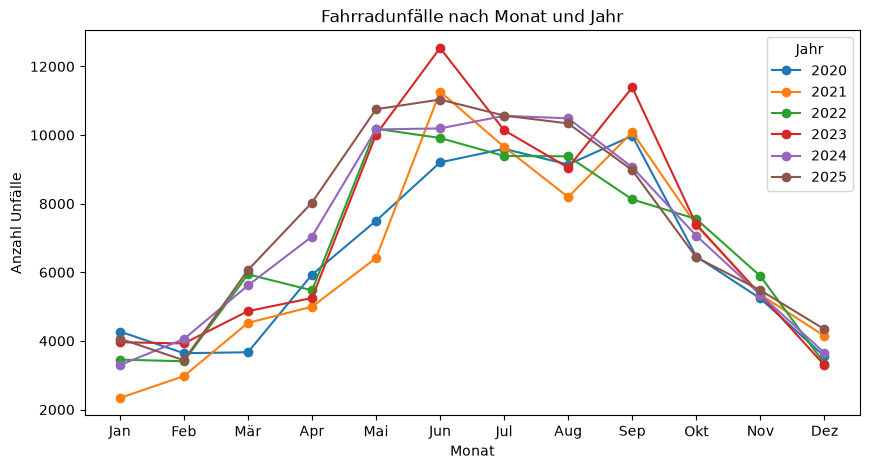

In [7]:
#  1.2 Entwicklung der Fahrradunfälle nach Monat

monate = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

rad_monat = df_rad.groupby(["UMONAT", "UJAHR"]).size().unstack()
print(rad_monat)
print(rad_monat.sum(axis=1).sort_values(ascending=False).head(3))  # Top-3-Monate


fig, ax = plt.subplots(figsize=(10, 5))
rad_monat.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(monate)
ax.set_title("Fahrradunfälle nach Monat und Jahr")
ax.set_xlabel("Monat")
ax.set_ylabel("Anzahl Unfälle")
ax.legend(title="Jahr");

Jan     4.3
Feb     4.3
Mär     6.1
Apr     7.3
Mai    11.0
Jun    12.8
Jul    12.0
Aug    11.3
Sep    11.5
Okt     8.4
Nov     6.5
Dez     4.5
dtype: float64
100.0


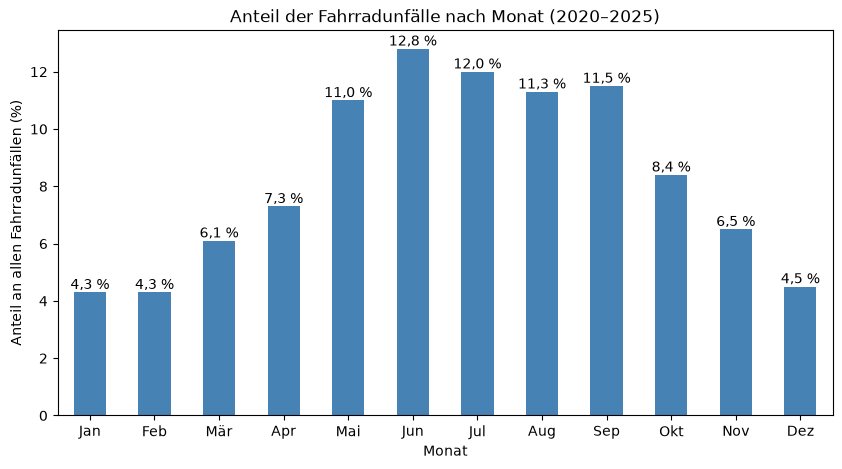

In [8]:
monat_summe = rad_monat.sum(axis=1)
anteil_monat = (monat_summe / monat_summe.sum() * 100).round(1)
anteil_monat.index = monate

print(anteil_monat)
print(anteil_monat.sum()) 

fig, ax = plt.subplots(figsize=(10, 5))
anteil_monat.plot(kind="bar", color="steelblue", ax=ax)
for i, v in enumerate(anteil_monat):
    ax.text(i, v, f"{v:.1f} %".replace(".", ","), ha="center", va="bottom")
ax.set_title("Anteil der Fahrradunfälle nach Monat (2020–2025)")
ax.set_xlabel("Monat")
ax.set_ylabel("Anteil an allen Fahrradunfällen (%)")
ax.tick_params(axis="x", rotation=0);

Fahrradunfälle zeigen eine deutliche saisonale Schwankung: Die meisten Unfälle passieren in den Sommermonaten. Über alle Jahre hinweg entfallen die meisten auf den Juni (12,8 %), gefolgt von Juli (12,0 %) und September (11,5 %). Auf die fünf Monate Mai bis September entfallen zusammen rund 59 % aller Fahrradunfälle. In den Wintermonaten Dezember bis Februar liegt der Anteil pro Monat dagegen nur bei 4,3 bis 4,5 %, zusammengenommen bei rund 13 %.

Das Muster wiederholt sich in allen Jahren, der Spitzenmonat variiert jedoch (2020: September, 2022: Mai, 2024: Juli, 2021, 2023 und 2025: Juni). Auffällig ist der Januar 2021 mit nur 2.337 Unfällen (Januar 2020: 4.274). Mögliche Ursachen wie Corona-Lockdown oder Witterung lassen sich anhand der Daten nicht belegen.

Die Häufung im Sommer zeigt, wann viele Menschen Rad fahren, nicht unbedingt, wann Radfahren am gefährlichsten ist. Daten zur tatsächlichen Fahrradnutzung liegen nicht vor.

Mo    74997
Di    81120
Mi    80839
Do    80949
Fr    77615
Sa    58520
So    46759
Name: count, dtype: int64
USTUNDE
16    47107
15    45561
17    43846
Name: count, dtype: int64


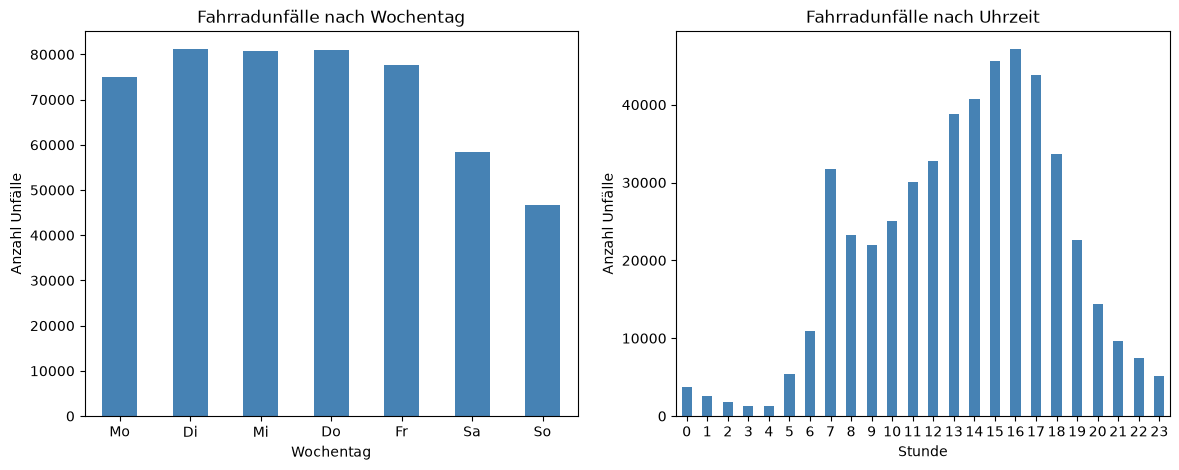

In [9]:
#  1.3 Entwicklung der Fahrradunfälle nach Wochentag und Tageszeit

tage = {2: "Mo", 3: "Di", 4: "Mi", 5: "Do", 6: "Fr", 7: "Sa", 1: "So"}
reihenfolge = [2, 3, 4, 5, 6, 7, 1]

# Wochentage
rad_tag = df_rad["UWOCHENTAG"].value_counts().reindex(reihenfolge)
rad_tag.index = [tage[i] for i in rad_tag.index]
print(rad_tag)

# Tageszeit
rad_stunde = df_rad["USTUNDE"].value_counts().sort_index()
print(rad_stunde.sort_values(ascending=False).head(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rad_tag.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Fahrradunfälle nach Wochentag")
axes[0].set_xlabel("Wochentag")
axes[0].set_ylabel("Anzahl Unfälle")
axes[0].tick_params(axis="x", rotation=0)

rad_stunde.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Fahrradunfälle nach Uhrzeit")
axes[1].set_xlabel("Stunde")
axes[1].set_ylabel("Anzahl Unfälle")
axes[1].tick_params(axis="x", rotation=0);

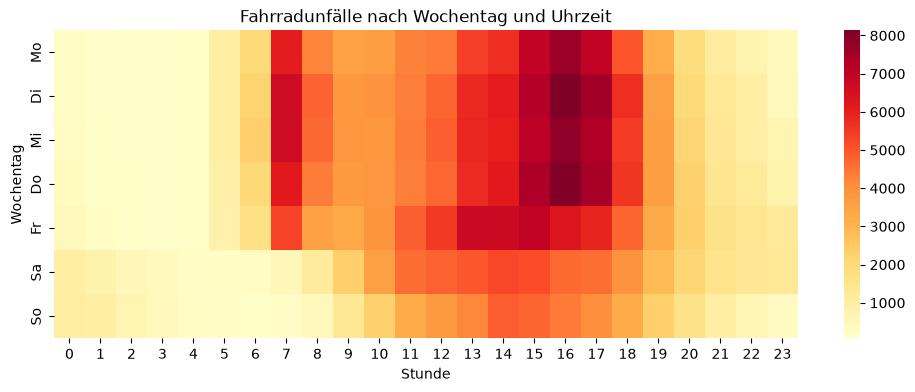

In [10]:
heat = (df_rad.pivot_table(index="UWOCHENTAG", columns="USTUNDE", values="IstRad", aggfunc="size")
              .reindex(reihenfolge))
heat.index = [tage[i] for i in heat.index]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heat, cmap="YlOrRd", ax=ax)
ax.set_title("Fahrradunfälle nach Wochentag und Uhrzeit")
ax.set_xlabel("Stunde")
ax.set_ylabel("Wochentag");

**Wochentage:** Fahrradunfälle passieren überwiegend werktags. Von Dienstag bis Donnerstag sind sie mit jeweils rund 81.000 Unfällen am häufigsten, am Montag (74.997) und Freitag (77.615) liegen sie etwas darunter. Am Wochenende sind es deutlich weniger: Samstag 58.520, Sonntag 46.759. Insgesamt passieren 395.520 Fahrradunfälle von Montag bis Freitag und 105.279 am Wochenende.

**Tageszeit:** Die meisten Fahrradunfälle ereignen sich am Nachmittag. Die Spitzenwerte liegen bei 16 Uhr (47.107), 15 Uhr (45.561) und 17 Uhr (43.846). Es gibt einen zweiten, kleineren Gipfel um 7 Uhr morgens (etwa 32.000), dazwischen ein Rückgang am Vormittag. In den Nachtstunden zwischen 1 und 4 Uhr passieren dagegen nur sehr wenige Unfälle.

**Kombination:** Die Heatmap zeigt zwei unterschiedliche Muster. Montag bis Donnerstag treten zwei Spitzen auf, morgens um 7 Uhr und am Nachmittag um 16 Uhr, was zu den üblichen Pendlerzeiten passt. Am Freitag verlagert sich die Häufung auf den frühen bis mittleren Nachmittag (etwa 13 bis 16 Uhr), die Morgenspitze ist schwächer. Am Wochenende fehlt die Morgenspitze, die Unfälle verteilen sich über den Tag mit einem Schwerpunkt am Nachmittag.

2. Räumliche Verteilung

                        Gesamt  Anteil (%)
Bundesland                                
Nordrhein-Westfalen     109796       21.92
Bayern                   95069       18.98
Baden-Württemberg        58337       11.65
Niedersachsen            48631        9.71
Berlin                   27751        5.54
Schleswig-Holstein       26068        5.21
Sachsen                  25631        5.12
Hessen                   23114        4.62
Brandenburg              16927        3.38
Hamburg                  16655        3.33
Rheinland-Pfalz          15498        3.09
Sachsen-Anhalt           12015        2.40
Mecklenburg-Vorpommern    8906        1.78
Thüringen                 7205        1.44
Bremen                    6081        1.21
Saarland                  3115        0.62


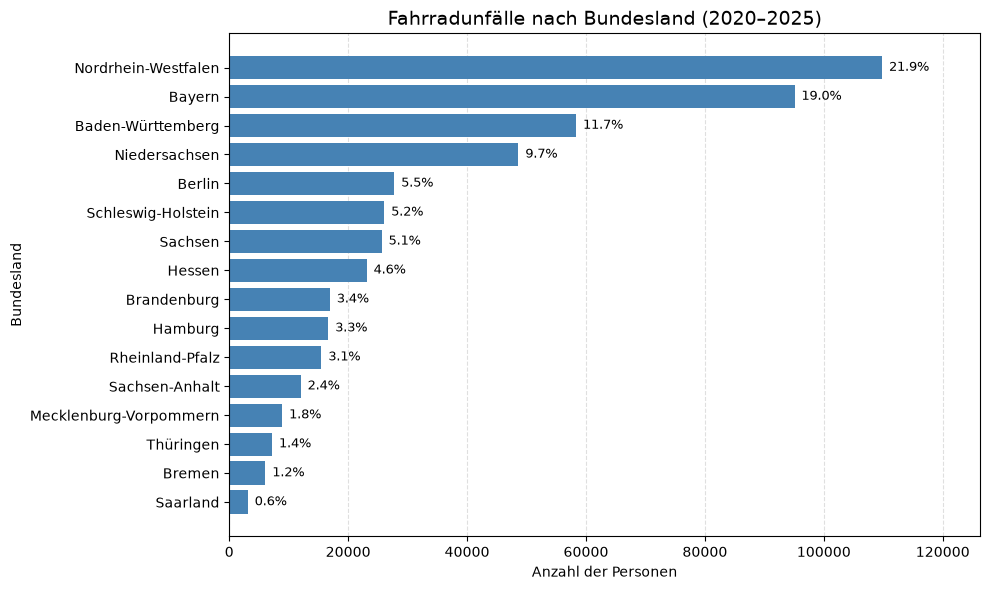

In [11]:
# 2.1.1 Fahrradunfälle nach Bundesland

laender = {
    1: "Schleswig-Holstein",
    2: "Hamburg",
    3: "Niedersachsen",
    4: "Bremen",
    5: "Nordrhein-Westfalen",
    6: "Hessen",
    7: "Rheinland-Pfalz",
    8: "Baden-Württemberg",
    9: "Bayern",
    10: "Saarland",
    11: "Berlin",
    12: "Brandenburg",
    13: "Mecklenburg-Vorpommern",
    14: "Sachsen",
    15: "Sachsen-Anhalt",
    16: "Thüringen",
}

df_rad["Bundesland"] = df_rad["ULAND"].map(laender)

land_gesamt = (df_rad["Bundesland"].value_counts().to_frame(name="Gesamt"))

# Prozentualer Anteil am Gesamtwert Deutschlands
land_gesamt["Anteil (%)"] = (land_gesamt["Gesamt"] / land_gesamt["Gesamt"].sum()* 100).round(2)
print(land_gesamt)

# Balkendiagramm
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(land_gesamt.index, land_gesamt["Gesamt"], color="steelblue")

# Prozentangaben rechts neben den Balken
for bar, prozent in zip(bars, land_gesamt["Anteil (%)"]):
    ax.annotate(
        f"{prozent:.1f}%",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Fahrradunfälle nach Bundesland (2020–2025)",
    fontsize=14
)
ax.set_xlabel("Anzahl der Personen")
ax.set_ylabel("Bundesland")
ax.invert_yaxis()
ax.set_xlim(0, land_gesamt["Gesamt"].max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();

401 True [5]
ars
01001     Flensburg (Kreisfreie Stadt)
01002          Kiel (Kreisfreie Stadt)
01003        Lübeck (Kreisfreie Stadt)
01004    Neumünster (Kreisfreie Stadt)
01051             Dithmarschen (Kreis)
dtype: str
Nicht zugeordnete Datensätze: 63 von 500799
Anteil an allen Datensätzen: 0.0126 %

Nicht zugeordnete Gebietsschlüssel:
ULAND  UREGBEZ  UKREIS  kreis_key
16     0        56      16056        63
Landkreis
Berlin (Kreisfreie Stadt)               27751
Hamburg (Kreisfreie Stadt)              16655
München (Kreisfreie Stadt)              14244
Köln (Kreisfreie Stadt)                 11108
Region Hannover (Landkreis)             10700
Dresden (Kreisfreie Stadt)               7000
Leipzig (Kreisfreie Stadt)               5531
Bremen (Kreisfreie Stadt)                5132
Düsseldorf (Kreisfreie Stadt)            4887
Frankfurt am Main (Kreisfreie Stadt)     4812
Nürnberg (Kreisfreie Stadt)              4387
Münster (Kreisfreie Stadt)               4364
Steinfurt (Kreis)     

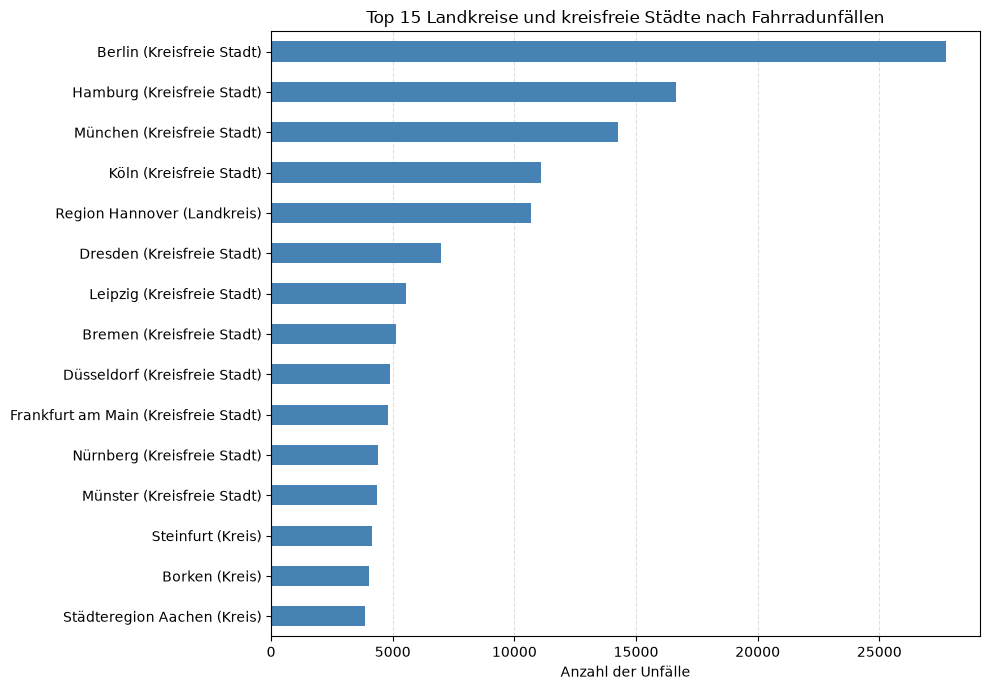

In [12]:
# 2.1.2 Fahrradunfälle nach Landkreis

# Verzeichnis einlesen
pfad = "data/20260131_Anschriften_der_Gemeinde_und_Stadtverwaltungen.xlsx"

raw = pd.read_excel(
    pfad,
    sheet_name="Anschriften_31_01_2026",
    header=None,
    dtype=str
)

gv = raw.iloc[6:, [2, 4, 5, 6, 7]].copy()
gv.columns = ["satzart", "art", "ars", "ags", "name"]

# Satzart 40 = Landkreise und kreisfreie Städte
kreise = gv[gv["satzart"] == "40"]

# Kontrolle
print(len(kreise), kreise["ars"].is_unique, kreise["ars"].str.len().unique())

# Schlüssel -> Name, z. B. "München (Kreisfreie Stadt)"
kreis_namen = (kreise["name"].str.split(",").str[0] + " (" + kreise["art"] + ")").set_axis(kreise["ars"])
print(kreis_namen.head())


# Schlüssel in den Unfalldaten
df_rad["kreis_key"] = (
    df_rad["ULAND"].astype(str).str.zfill(2)
    + df_rad["UREGBEZ"].astype(str)
    + df_rad["UKREIS"].astype(str).str.zfill(2)
)

# Berlin und Hamburg sind in den Unfalldaten in Bezirke unterteilt -> eine Stadt
df_rad["kreis_key"] = df_rad["kreis_key"].mask(df_rad["ULAND"] == 11, "11000")
df_rad["kreis_key"] = df_rad["kreis_key"].mask(df_rad["ULAND"] == 2, "02000")

df_rad["Landkreis"] = df_rad["kreis_key"].map(kreis_namen)

# Kontrolle der Zuordnung 
nicht_gefunden = df_rad["Landkreis"].isna()

print("Nicht zugeordnete Datensätze:", nicht_gefunden.sum(), "von", len(df_rad))
print("Anteil an allen Datensätzen:", round(nicht_gefunden.mean() * 100, 4), "%")
print("\nNicht zugeordnete Gebietsschlüssel:")
print(
    df_rad.loc[nicht_gefunden, ["ULAND", "UREGBEZ", "UKREIS", "kreis_key"]]
    .value_counts()
    .to_string()
)

# Diagramm
top_kreise = df_rad["Landkreis"].value_counts().head(15)
print(top_kreise)

fig, ax = plt.subplots(figsize=(10, 7))
top_kreise.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Landkreise und kreisfreie Städte nach Fahrradunfällen")
ax.set_xlabel("Anzahl der Unfälle")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();


Bei der Zuordnung der Unfalldaten zu den Landkreisen und kreisfreien Städten 
konnten 63 von insgesamt 500.799 Datensätzen (ca. 0,013 %) nicht zugeordnet werden. 
Alle 63 Datensätze weisen den Gebietsschlüssel 16056 auf, der im verwendeten 
Verwaltungsverzeichnis vom Januar 2026 nicht enthalten ist. Dies hängt vermutlich 
mit einer Änderung der Verwaltungsstruktur zusammen. Da der Anteil der nicht 
zugeordneten Datensätze sehr gering ist, wurden sie für die Auswertung nach 
Landkreisen nicht berücksichtigt.

10749 0 [8] True
Gemeinde nicht gefunden: 618 von 500799
Anteil: 0.123 %
gemeinde_key
06435014    464
16056000     63
03153007     13
03153504     13
16064055      6
Name: count, dtype: int64
Berlin                  27751
Hamburg                 16655
München                 14244
Köln                    11108
Dresden                  7000
Hannover                 6618
Leipzig                  5531
Bremen                   5132
Düsseldorf               4887
Frankfurt am Main        4812
Nürnberg                 4387
Münster                  4364
Freiburg im Breisgau     3563
Augsburg                 3443
Bonn                     3355
Name: count, dtype: int64


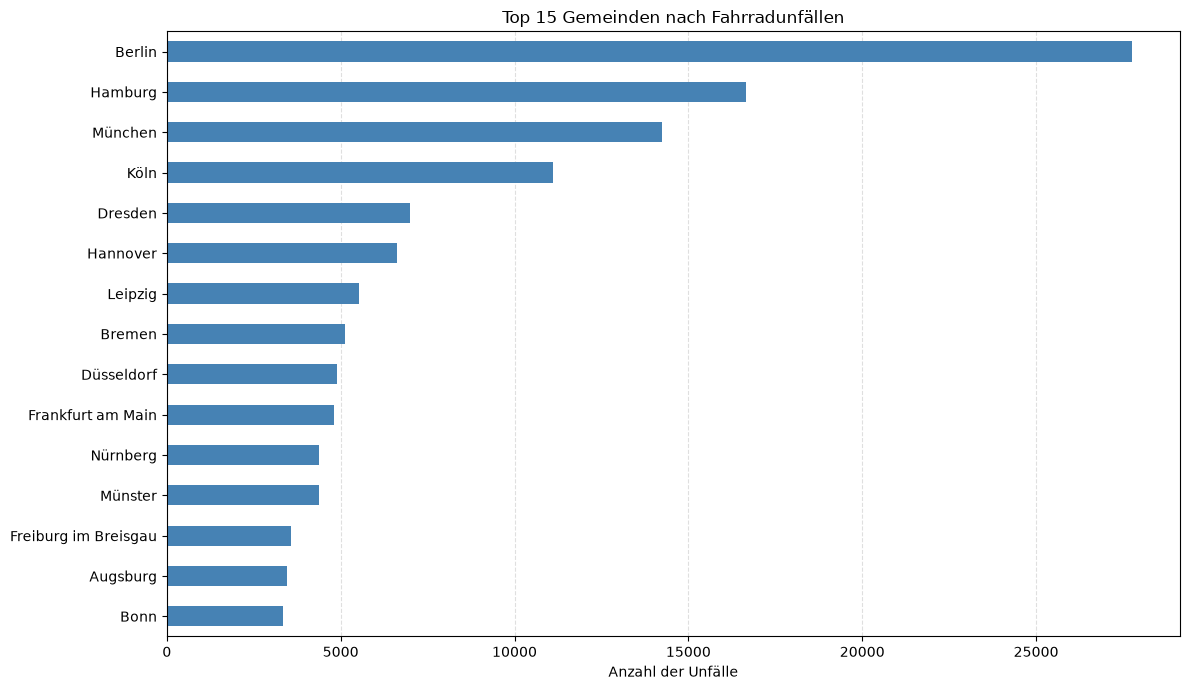

In [13]:
# 2.1.3 Fahrradunfälle nach Gemeinden

# Gemeinden aus dem Verzeichnis (Satzart 60), Doppelzeilen entfernen
gemeinden = gv[gv["satzart"] == "60"].drop_duplicates(subset="ags")

# Kontrolle: keine leeren Schlüssel, alle 8-stellig, eindeutig
print(len(gemeinden), gemeinden["ags"].isna().sum(), gemeinden["ags"].str.len().unique(), gemeinden["ags"].is_unique)


# Schlüssel -> Name (nur der Teil vor dem Komma)
gemeinde_namen = gemeinden.set_index("ags")["name"].str.split(",").str[0]

# Schlüssel in den Unfalldaten
df_rad["gemeinde_key"] = df_rad["kreis_key"] + df_rad["UGEMEINDE"].astype(str).str.zfill(3)

# Berlin und Hamburg: in den Unfalldaten in Bezirke unterteilt -> eine Gemeinde
df_rad.loc[df_rad["ULAND"] == 11, "gemeinde_key"] = "11000000"
df_rad.loc[df_rad["ULAND"] == 2, "gemeinde_key"] = "02000000"

df_rad["Gemeinde"] = df_rad["gemeinde_key"].map(gemeinde_namen)

# Kontrolle der Zuordnung 
nicht_gefunden = df_rad["Gemeinde"].isna()
print("Gemeinde nicht gefunden:", nicht_gefunden.sum(), "von", len(df_rad))
print("Anteil:", round(nicht_gefunden.mean() * 100, 3), "%")
print(df_rad.loc[nicht_gefunden, "gemeinde_key"].value_counts().head())

# Top 15 nach Schlüssel zählen (gleichnamige Gemeinden bleiben getrennt)
top_gemeinden = df_rad["gemeinde_key"].value_counts().head(15)
top_gemeinden.index = [gemeinde_namen.get(k, k) for k in top_gemeinden.index]
print(top_gemeinden)

fig, ax = plt.subplots(figsize=(12, 7))
top_gemeinden.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Gemeinden nach Fahrradunfällen")
ax.set_xlabel("Anzahl der Unfälle")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout();


Zuordnung der Gemeinden

Die Zuordnung der Gemeinden erfolgte anhand des Gemeindeschlüssels, 
der aus dem Kreisschlüssel (kreis_key) und dem Gemeindecode (UGEMEINDE) gebildet wurde.
Die Zuordnung der Gemeindenamen erfolgte mithilfe des Verwaltungsverzeichnisses.
Von insgesamt 500.799 Unfallmeldungen konnten 500.181 (99,877 %) einer Gemeinde 
zugeordnet werden. Bei 618 Unfallmeldungen (0,123 %) war keine eindeutige Zuordnung
möglich. Diese Datensätze wurden keiner Gemeinde zugewiesen, 
um fehlerhafte Zuordnungen zu vermeiden.

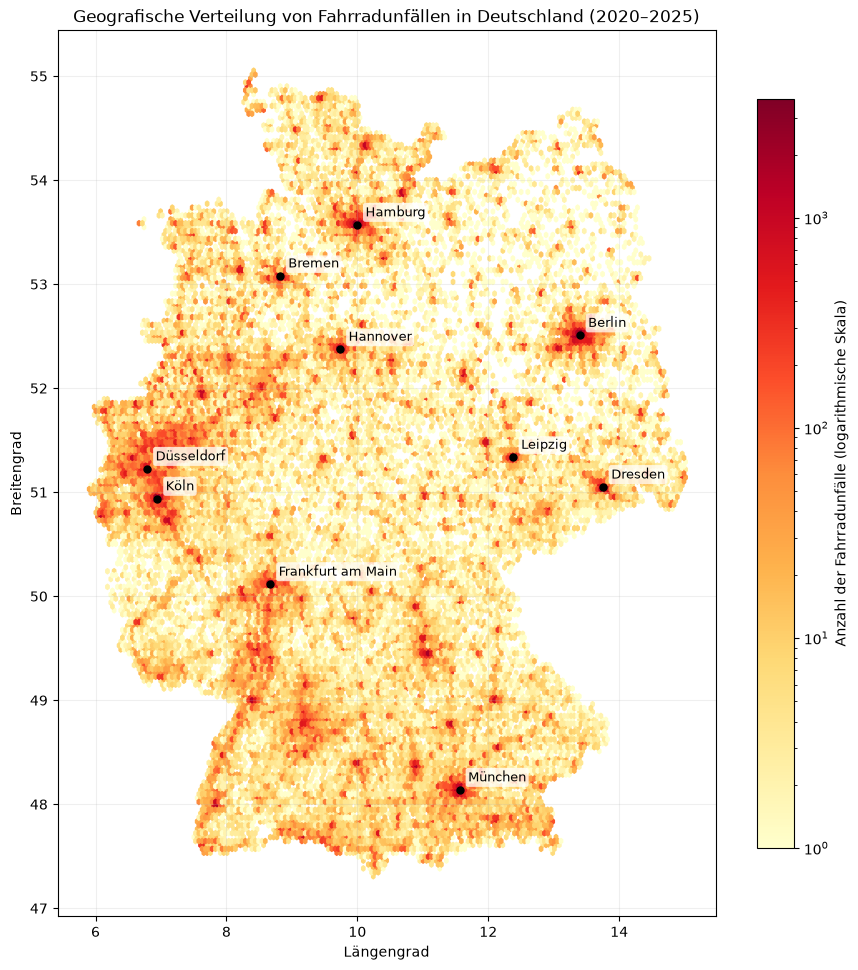

In [14]:

# 2.2 Geografische Verteilung und Häufung von Fahrradunfällen

# Die 10 Gemeinden mit den meisten Fahrradunfällen bestimmen
n_staedte = 10

top_keys = df_rad["gemeinde_key"].value_counts().head(n_staedte).index

# Median der Unfallkoordinaten je Gemeinde berechnen
zentren = (
    df_rad[df_rad["gemeinde_key"].isin(top_keys)]
    .groupby("gemeinde_key")[["XGCSWGS84", "YGCSWGS84"]]
    .median()
)

# Gemeindenamen ergänzen
zentren["Name"] = [
    gemeinde_namen.get(k, k) for k in zentren.index
]

# Karte der geografischen Unfallhäufungen erstellen
fig, ax = plt.subplots(figsize=(9, 11))

hb = ax.hexbin(
    df_rad["XGCSWGS84"],
    df_rad["YGCSWGS84"],
    gridsize=180,
    bins="log",
    mincnt=1,
    cmap="YlOrRd",
)

fig.colorbar(
    hb,
    ax=ax,
    label="Anzahl der Fahrradunfälle (logarithmische Skala)",
    shrink=0.7,
)

# Die 10 Gemeinden auf der Karte markieren und beschriften
for _, row in zentren.iterrows():
    ax.scatter(
        row["XGCSWGS84"],
        row["YGCSWGS84"],
        s=25,
        color="black",
        zorder=3,
    )

    ax.annotate(
        row["Name"],
        xy=(row["XGCSWGS84"], row["YGCSWGS84"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
        zorder=4,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.75,
        ),
    )

# Achsen und Darstellung formatieren
ax.set_aspect(1 / np.cos(np.radians(51)))
ax.set_xlabel("Längengrad")
ax.set_ylabel("Breitengrad")
ax.set_title("Geografische Verteilung von Fahrradunfällen in Deutschland (2020–2025)")
ax.grid(alpha=0.2)
plt.tight_layout();


    UKATEGORIE  schwer
2            3   False
4            3   False
5            3   False
9            3   False
15           2    True
schwer
False    416636
True      84163
Name: count, dtype: int64
                        Anzahl_Unfaelle  Schwere_Unfaelle  \
Bundesland                                                  
Saarland                           3115               705   
Thüringen                          7205              1608   
Sachsen                           25631              5414   
Bayern                            95069             18170   
Rheinland-Pfalz                   15498              2951   
Baden-Württemberg                 58337             10848   
Mecklenburg-Vorpommern             8906              1596   
Sachsen-Anhalt                    12015              2103   
Hessen                            23114              3995   
Brandenburg                       16927              2906   
Nordrhein-Westfalen              109796             17628   
Nied

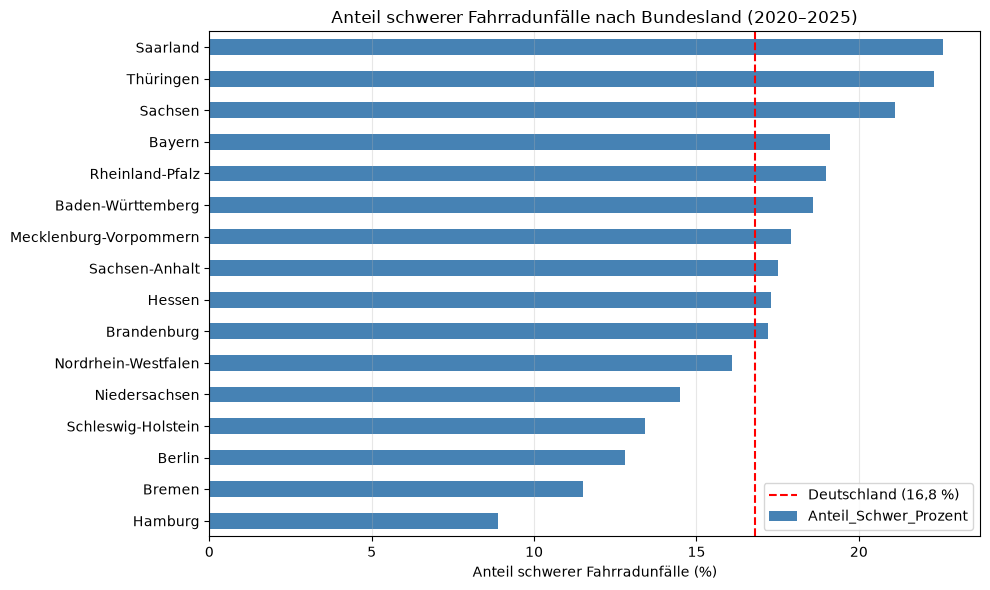

In [15]:

# 2.3 Anteil schwerer Fahrradunfälle nach Region

# Schwere Fahrradunfälle kennzeichnen
df_rad["schwer"] = df_rad["UKATEGORIE"].isin([1, 2])

# Ergebnis prüfen
print(df_rad[["UKATEGORIE", "schwer"]].head())
print(df_rad["schwer"].value_counts(dropna=False))


# Anteil schwerer Fahrradunfälle nach Bundesland berechnen

anteil_bundesland = (
    df_rad.groupby("Bundesland")
    .agg(
        Anzahl_Unfaelle=("schwer", "size"),
        Schwere_Unfaelle=("schwer", "sum"),
        Anteil_Schwer_Prozent=("schwer", "mean"),
    )
)

anteil_bundesland["Anteil_Schwer_Prozent"] *= 100

anteil_bundesland = anteil_bundesland.round(1)
anteil_bundesland = anteil_bundesland.sort_values(
    "Anteil_Schwer_Prozent", ascending=False
)

print(anteil_bundesland)


anteil_de = df_rad["schwer"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))
anteil_bundesland["Anteil_Schwer_Prozent"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(anteil_de, color="red", linestyle="--",
           label=f"Deutschland ({anteil_de:.1f} %)".replace(".", ","))
ax.set_xlabel("Anteil schwerer Fahrradunfälle (%)")
ax.set_ylabel("")
ax.set_title("Anteil schwerer Fahrradunfälle nach Bundesland (2020–2025)")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout();


In [16]:
df_rad["schwer"] = df_rad["UKATEGORIE"].isin([1, 2]).astype(int)

dynamik_bundesland = (
    df_rad.groupby(["UJAHR", "Bundesland"])
    .agg(
        Anzahl_Unfaelle=("schwer", "size"),
        Schwere_Unfaelle=("schwer", "sum"),
        Anteil_Schwer_Prozent=("schwer", "mean")
    )
    .reset_index()
)

dynamik_bundesland["Anteil_Schwer_Prozent"] *= 100

tabelle_dynamik = dynamik_bundesland.pivot(
    index="Bundesland",
    columns="UJAHR",
    values="Anteil_Schwer_Prozent"
).sort_index(axis=1).round(1)

tabelle_dynamik

UJAHR,2020,2021,2022,2023,2024,2025
Bundesland,,,,,,
Baden-Württemberg,21.2,21.5,18.3,18.1,17.7,15.8
Bayern,21.3,21.7,18.4,18.3,18.2,17.2
Berlin,13.3,13.6,13.3,12.7,12.0,11.7
Brandenburg,20.5,18.7,16.5,16.3,16.2,14.8
Bremen,14.9,12.9,10.5,12.0,11.5,6.5
Hamburg,9.2,9.9,9.2,8.4,8.9,7.9
Hessen,19.2,19.1,17.7,16.8,16.0,15.5
Mecklenburg-Vorpommern,18.9,17.1,20.2,18.4,16.9,16.1
Niedersachsen,15.6,15.7,14.6,14.0,13.5,13.5


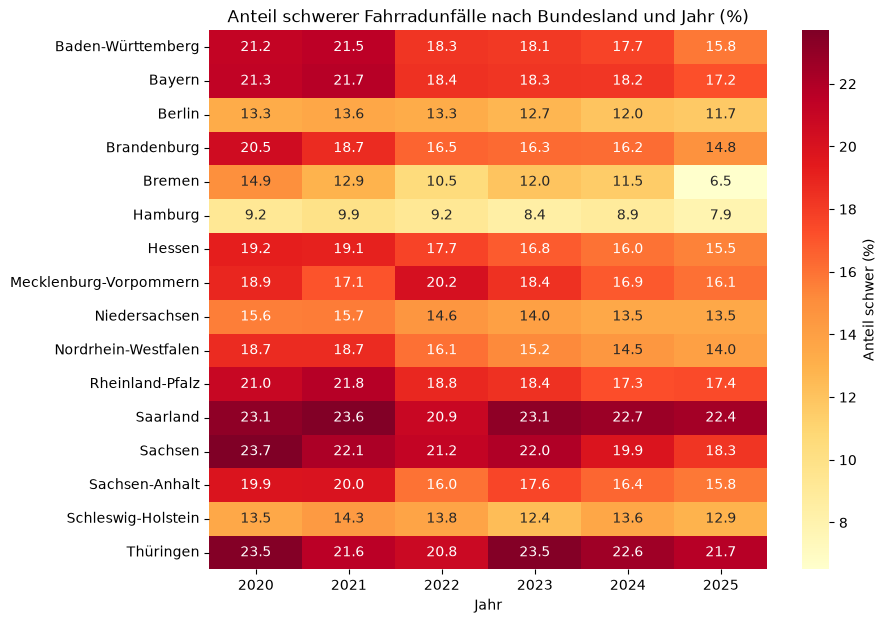

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(tabelle_dynamik, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Anteil schwer (%)"}, ax=ax)
ax.set_title("Anteil schwerer Fahrradunfälle nach Bundesland und Jahr (%)")
ax.set_xlabel("Jahr")
ax.set_ylabel("");

Fazit: Anteil schwerer Fahrradunfälle nach Bundesland (2020–2025)

Regionale Unterschiede. 
Es gibt Bundesländer mit besonders hohen Anteilen schwerer Fahrradunfälle. Im Durchschnitt endeten 16,8 % der Fahrradunfälle mit Getöteten oder Schwerverletzten. Deutlich darüber liegen das Saarland (22,6 %), Thüringen (22,3 %) und Sachsen (21,1 %). Die niedrigsten Anteile haben die Stadtstaaten Hamburg (8,9 %), Bremen (11,5 %) und Berlin (12,8 %) sowie Schleswig-Holstein (13,4 %).

Entwicklung. 
Zwischen 2020 und 2025 ist der Anteil schwerer Fahrradunfälle in allen 16 Bundesländern zurückgegangen. Am deutlichsten war der Rückgang in Bremen (von 14,9 % auf 6,5 %), Brandenburg (von 20,5 % auf 14,8 %) sowie in Baden-Württemberg und Sachsen (jeweils um 5,4 Prozentpunkte). Am geringsten fiel er in Schleswig-Holstein (−0,6) und im Saarland (−0,7) aus. Im Jahr 2025 verzeichneten das Saarland (22,4 %) und Thüringen (21,7 %) weiterhin die höchsten Anteile, die niedrigsten Werte hatten Bremen (6,5 %) und Hamburg (7,9 %). In mehreren Ländern, darunter Mecklenburg-Vorpommern, Thüringen, das Saarland und Bremen, verlief der Rückgang nicht gleichmäßig, sondern mit Schwankungen zwischen den Jahren.


In [59]:
# 2.3 Schwere Fahrradunfälle: Bundesländer und die 10 einwohnerstärksten Städte

def lese_einwohner(pfad):
    """Gemeinden (Satzart 60) mit Schlüssel, Name und Einwohnerzahl aus einer Auszug_GV-Datei."""
    sheets = pd.read_excel(pfad, sheet_name=None, header=None, dtype=str)
    t = sheets[max(sheets, key=lambda s: len(sheets[s]))]     # größtes Blatt = Gemeinden
    t = t[t[0] == "60"]                                       # Satzart 60 = Gemeinden
    out = pd.DataFrame({
        "key": t[2].str.zfill(2) + t[3].str.zfill(1) + t[4].str.zfill(2) + t[6].str.zfill(3),
        "name": t[7].str.split(",").str[0],
        "einwohner": pd.to_numeric(t[9].str.replace(r"\s+", "", regex=True), errors="coerce"),
    })
    return out.drop_duplicates(subset="key").set_index("key")

einw_jahre = {j: lese_einwohner(f"data/population/3112{j}_Auszug_GV.xlsx") for j in range(2020, 2026)}

# Kontrolle: Anzahl Gemeinden und fehlende Einwohnerzahlen je Jahr (erwartet: 0)
print({j: (len(t), int(t["einwohner"].isna().sum())) for j, t in einw_jahre.items()})

{2020: (11004, 0), 2021: (10997, 0), 2022: (10993, 0), 2023: (10981, 0), 2024: (10959, 0), 2025: (10953, 0)}


In [60]:
df_rad["schwer"] = df_rad["UKATEGORIE"].isin([1, 2])

ergebnisse = []
for jahr in range(2020, 2026):
    # 10 einwohnerstärkste Gemeinden dieses Jahres
    top10 = einw_jahre[jahr].nlargest(10, "einwohner").copy()
    d = df_rad[df_rad["UJAHR"] == jahr]

    # Fahrradunfälle dieses Jahres je Gemeinde (0, falls keine)
    alle = d.groupby("gemeinde_key").size()
    schwer = d[d["schwer"]].groupby("gemeinde_key").size()

    top10["Unfaelle"] = alle.reindex(top10.index, fill_value=0)
    top10["Schwere_Unfaelle"] = schwer.reindex(top10.index, fill_value=0)
    top10["Anteil_schwer_%"] = (top10["Schwere_Unfaelle"] / top10["Unfaelle"] * 100).round(1)
    top10["Schwere_pro_100000"] = (top10["Schwere_Unfaelle"] / top10["einwohner"] * 100_000).round(1)
    top10["Jahr"] = jahr
    ergebnisse.append(top10.rename(columns={"name": "Gemeinde", "einwohner": "Einwohner"}))

alle_daten = pd.concat(ergebnisse, ignore_index=True)

def tabelle(jahr):
    """Tabelle der 10 einwohnerstärksten Gemeinden eines Jahres."""
    return (alle_daten[alle_daten["Jahr"] == jahr]
            .set_index("Gemeinde")[["Einwohner", "Unfaelle", "Schwere_Unfaelle", "Anteil_schwer_%", "Schwere_pro_100000"]]
            .sort_values("Schwere_pro_100000", ascending=False))

tabelle(2020)
# tabelle(2021)
# tabelle(2022)
# tabelle(2023)
# tabelle(2024)
# tabelle(2025)


,Einwohner,Unfaelle,Schwere_Unfaelle,Anteil_schwer_%,Schwere_pro_100000
Gemeinde,,,,,
Köln,1083498,1783,266,14.9,24.6
Leipzig,597493,857,119,13.9,19.9
Berlin,3664088,5109,677,13.3,18.5
München,1488202,2351,263,11.2,17.7
Düsseldorf,620523,859,97,11.3,15.6
Frankfurt am Main,764104,798,108,13.5,14.1
Stuttgart,630305,475,86,18.1,13.6
Hamburg,1852478,2479,229,9.2,12.4
Essen,582415,340,55,16.2,9.4


In [61]:
dynamik = alle_daten.pivot(index="Gemeinde", columns="Jahr", values="Schwere_pro_100000")
dynamik = dynamik.loc[dynamik.mean(axis=1).sort_values(ascending=False).index]   # hohe Werte oben
dynamik["Jahre in Top 10"] = dynamik.notna().sum(axis=1)
display(dynamik)

# Städte, die 2020 und 2025 in den Top 10 waren
vergleich = dynamik[[2020, 2025]].dropna().copy()
vergleich["Veränderung"] = (vergleich[2025] - vergleich[2020]).round(1)
vergleich["Entwicklung"] = pd.cut(
    vergleich["Veränderung"],
    bins=[-float("inf"), -1, 1, float("inf")],
    labels=["gesunken", "kaum verändert", "gestiegen"],
)
display(vergleich.sort_values("Veränderung"))

Jahr,2020,2021,2022,2023,2024,2025,Jahre in Top 10
Gemeinde,,,,,,,
Köln,24.6,22.4,19.7,21.5,20.7,18.5,6
Leipzig,19.9,16.8,21.3,19.7,17.3,17.0,6
Düsseldorf,15.6,17.6,16.7,16.6,13.7,15.7,6
Berlin,18.5,15.9,16.5,15.0,14.5,15.1,6
München,17.7,16.9,15.3,14.3,14.2,14.0,6
Frankfurt am Main,14.1,12.8,12.3,12.2,14.3,14.1,6
Hamburg,12.4,13.9,14.1,13.0,13.6,12.1,6
Bremen,NaN,NaN,NaN,NaN,16.2,8.8,2
Stuttgart,13.6,10.7,7.6,12.6,12.7,12.5,6


Jahr,2020,2025,Veränderung,Entwicklung
Gemeinde,,,,
Köln,24.6,18.5,-6.1,gesunken
München,17.7,14.0,-3.7,gesunken
Berlin,18.5,15.1,-3.4,gesunken
Leipzig,19.9,17.0,-2.9,gesunken
Stuttgart,13.6,12.5,-1.1,gesunken
Dortmund,8.2,7.2,-1.0,gesunken
Hamburg,12.4,12.1,-0.3,kaum verändert
Frankfurt am Main,14.1,14.1,0.0,kaum verändert
Düsseldorf,15.6,15.7,0.1,kaum verändert


In [62]:
dynamik_anteil = alle_daten.pivot(index="Gemeinde", columns="Jahr", values="Anteil_schwer_%")
dynamik_anteil = dynamik_anteil.loc[dynamik.index]     # gleiche Reihenfolge wie oben
display(dynamik_anteil)

Jahr,2020,2021,2022,2023,2024,2025
Gemeinde,,,,,,
Köln,14.9,14.3,12.3,11.9,11.1,9.4
Leipzig,13.9,12.3,13.4,13.3,11.1,10.4
Düsseldorf,11.3,14.8,14.2,12.4,10.2,11.1
Berlin,13.3,13.6,13.3,12.7,12.0,11.7
München,11.2,11.1,10.0,8.7,9.1,8.4
Frankfurt am Main,13.5,13.3,11.9,12.6,13.0,11.8
Hamburg,9.2,9.9,9.2,8.4,8.9,7.9
Bremen,NaN,NaN,NaN,NaN,11.8,6.6
Stuttgart,18.1,14.0,11.1,15.5,14.0,15.2


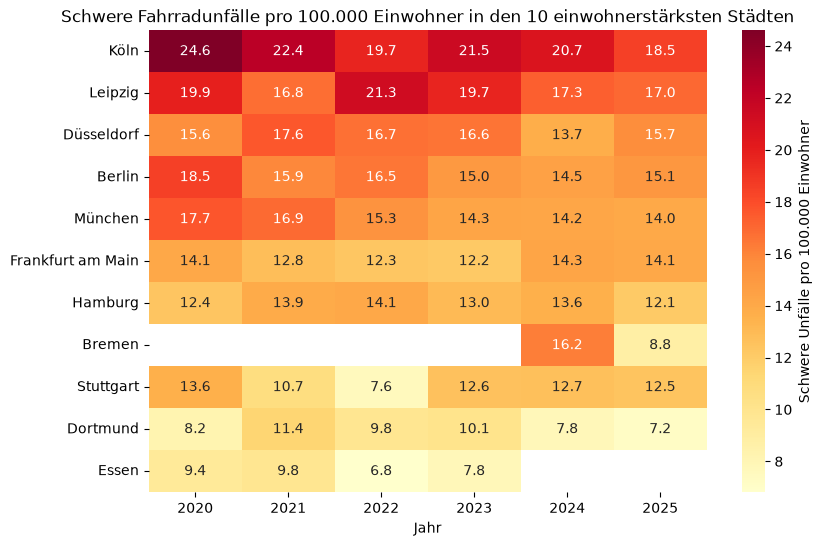

In [64]:
# Heatmap: Städte (Zeilen) x Jahre (Spalten), leere Felder = nicht in den Top 10
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(dynamik[list(range(2020, 2026))], annot=True, fmt=".1f", cmap="YlOrRd",
            cbar_kws={"label": "Schwere Unfälle pro 100.000 Einwohner"}, ax=ax)
ax.set_title("Schwere Fahrradunfälle pro 100.000 Einwohner in den 10 einwohnerstärksten Städten")
ax.set_xlabel("Jahr")
ax.set_ylabel("");

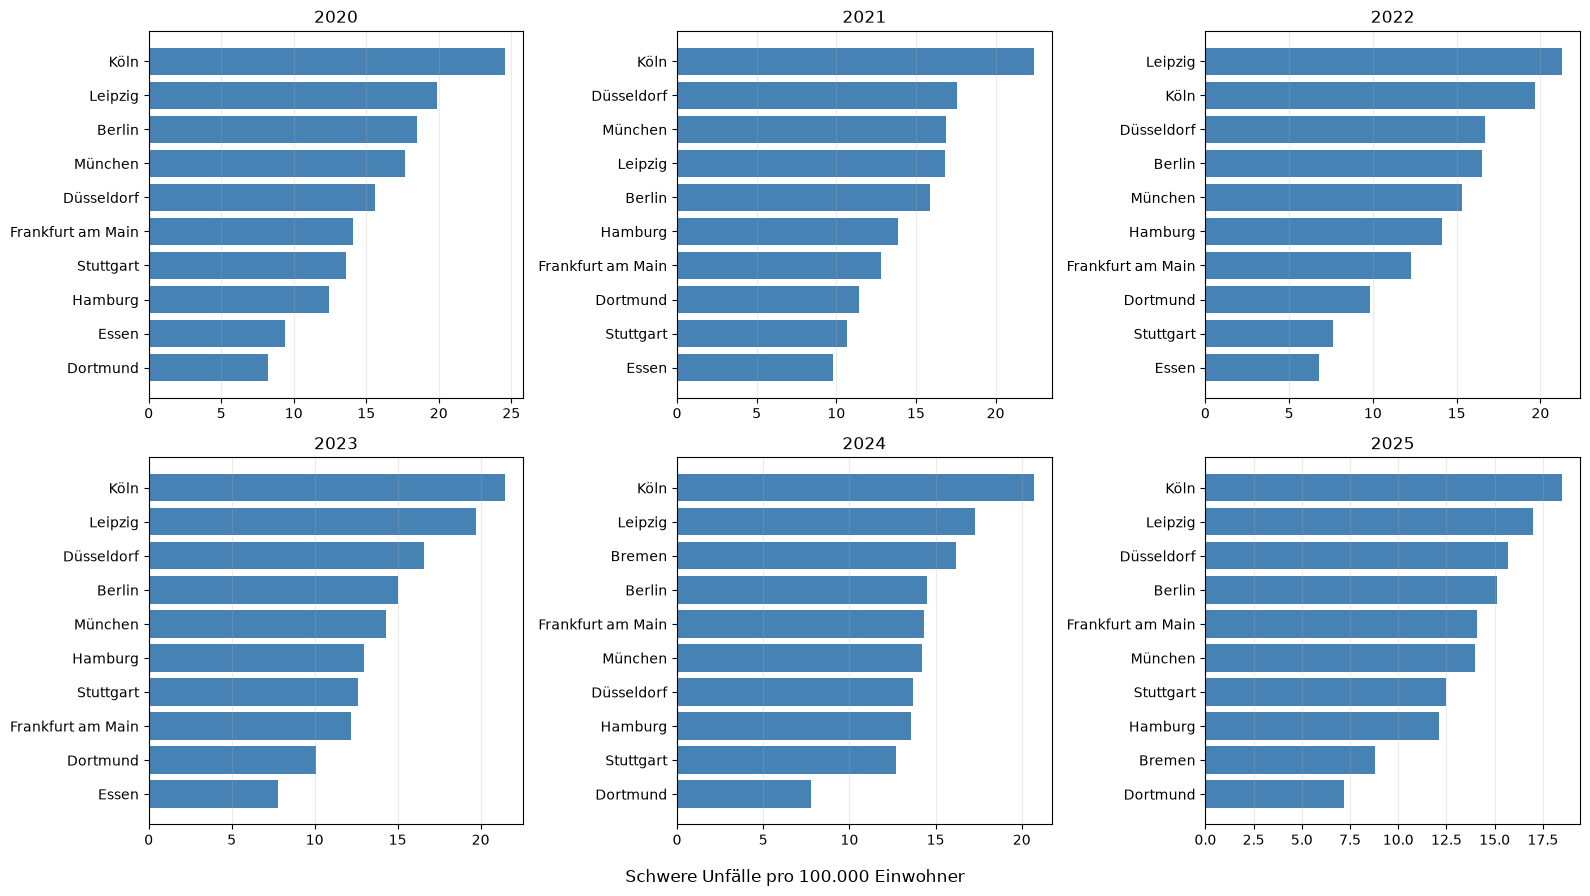

In [65]:
# Sechs Jahre nebeneinander
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, jahr in zip(axes.ravel(), range(2020, 2026)):
    d = tabelle(jahr).sort_values("Schwere_pro_100000")
    ax.barh(d.index, d["Schwere_pro_100000"], color="steelblue")
    ax.set_title(jahr)
    ax.grid(axis="x", alpha=0.25)
fig.supxlabel("Schwere Unfälle pro 100.000 Einwohner")
plt.tight_layout();

### Fazit: Schwere Fahrradunfälle pro 100.000 Einwohner in den zehn einwohnerstärksten Städten (2020–2025)

**Wo der Wert hoch bleibt.** Köln hat in fünf von sechs Jahren den höchsten Wert (nur 2022 lag Leipzig mit 21,3 vorn) und liegt auch 2025 mit 18,5 an der Spitze. Es folgen Leipzig (17,0), Düsseldorf (15,7) und Berlin (15,1). Düsseldorf bewegt sich im gesamten Zeitraum zwischen 13,7 und 17,6, ohne klaren Trend.

**Wo der Wert niedrig bleibt.** Dortmund hat 2025 mit 7,2 den niedrigsten Wert unter den Städten, die in allen sechs Jahren zu den zehn größten gehörten. Auch Essen lag in den Jahren 2020 bis 2023 mit 6,8 bis 9,8 niedrig. Stuttgart (12,5) und Hamburg (12,1) liegen im mittleren Bereich.

**Wo der Wert sinkt.** Am deutlichsten ging der Wert in Köln zurück (von 24,6 auf 18,5; −6,1), gefolgt von München (−3,7), Berlin (−3,4) und Leipzig (−2,9). In München sank er in jedem Jahr, von 17,7 auf 14,0. Ein leichter Rückgang zeigt sich in Stuttgart (−1,1) und Dortmund (−1,0). Kaum verändert hat sich der Wert in Hamburg (−0,3), Frankfurt am Main (0,0) und Düsseldorf (+0,1). In Frankfurt sank er zunächst bis 2023 auf 12,2 und stieg 2024 wieder auf 14,3.

**Bremen und Essen.** Bremen gehört nur 2024 und 2025 zu den zehn größten Städten. Der Wert fiel von 16,2 auf 8,8, das entspricht einem Rückgang von 95 auf 52 schwere Unfälle. Essen war nur von 2020 bis 2023 dabei (9,4 auf 7,8). Für beide Städte ist daher kein Vergleich über den gesamten Zeitraum möglich.

**Einordnung.** Da sich die zehn größten Städte von Jahr zu Jahr ändern, sind nicht alle Städte über den gesamten Zeitraum direkt vergleichbar. Die Kennzahl bezieht sich auf die Einwohnerzahl und nicht auf die Zahl der Radfahrenden, beschreibt also nicht das individuelle Unfallrisiko. Unfälle werden am Unfallort gezählt, auch wenn die Beteiligten nicht in der Stadt wohnen. In kleineren Städten wie Dortmund und Stuttgart beruhen die Werte auf nur etwa 40 bis 90 schweren Unfällen pro Jahr, Veränderungen von etwa einem Punkt können deshalb auch zufällig sein.

,Anzahl,Anteil_%
UKATEGORIE,,
Mit Getöteten,2437,0.5
Mit Schwerverletzten,81726,16.3
Mit Leichtverletzten,416636,83.2


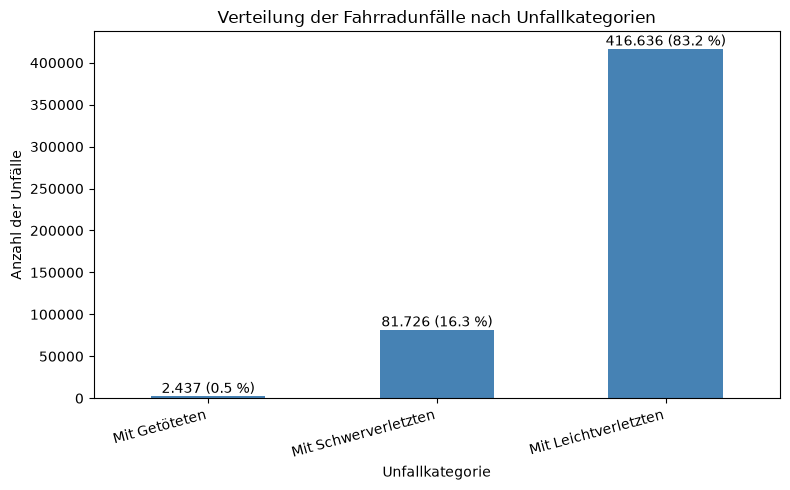

In [138]:
# 3.1 Verteilung der Fahrradunfälle nach Unfallkategorien

kategorien_namen = {
    1: "Mit Getöteten",
    2: "Mit Schwerverletzten",
    3: "Mit Leichtverletzten"
}

# Anzahl der Fahrradunfälle je Unfallkategorie
kategorien = df_rad["UKATEGORIE"].value_counts().sort_index()

# Prozentualer Anteil je Kategorie
anteile = (kategorien / kategorien.sum() * 100).round(1)

# Ergebnistabelle
verteilung = pd.DataFrame({
    "Anzahl": kategorien,
    "Anteil_%": anteile
})
verteilung.index = verteilung.index.map(kategorien_namen)


display(verteilung)

# Diagramm: Verteilung nach Unfallkategorien


ax = kategorien.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f"{anzahl:,} ({anteil:.1f} %)".replace(",", ".")
        for anzahl, anteil in zip(kategorien, anteile)
    ]
)
ax.set_xticks(range(len(kategorien)))
ax.set_xticklabels(
    [kategorien_namen.get(k, str(k)) for k in kategorien.index],
    rotation=15,
    ha="right"
)

plt.title("Verteilung der Fahrradunfälle nach Unfallkategorien")
plt.xlabel("Unfallkategorie")
plt.ylabel("Anzahl der Unfälle")
plt.tight_layout();


In [126]:
# Unfallschwere nach Tageszeit und Lichtverhältnissen
# 3.2 Unfallschwere nach Tageszeit

def schwere_nach_gruppe(df, spalte):
    """Berechnet Anzahl und Anteil schwerer Fahrradunfälle je Gruppe."""
    ergebnis = df.groupby(spalte, dropna=False).agg(
        Unfaelle=("schwer", "size"),
        Schwere_Unfaelle=("schwer", "sum")
    )

    ergebnis["Anteil_schwer_%"] = (
        ergebnis["Schwere_Unfaelle"] / ergebnis["Unfaelle"] * 100
    ).round(1)

    return ergebnis


# Schwere Fahrradunfälle nach Tageszeit
nach_stunde = schwere_nach_gruppe(df_rad, "USTUNDE")
display(nach_stunde)

,Unfaelle,Schwere_Unfaelle,Anteil_schwer_%
USTUNDE,,,
0,3741,925,24.7
1,2566,668,26.0
2,1782,420,23.6
3,1326,337,25.4
4,1292,276,21.4
5,5373,949,17.7
6,10881,1663,15.3
7,31722,3618,11.4
8,23289,3064,13.2


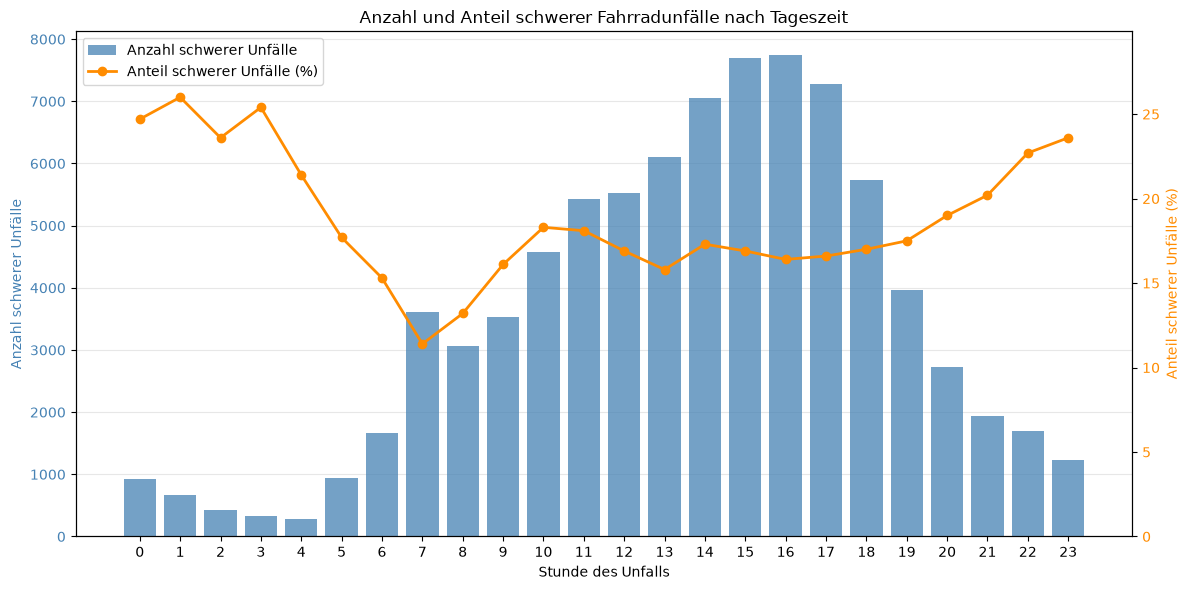

In [129]:
# Gemeinsames Diagramm 
fig, ax1 = plt.subplots(figsize=(12, 6))

# Balken: Anzahl schwerer Unfälle
ax1.bar(
    nach_stunde.index,
    nach_stunde["Schwere_Unfaelle"],
    color="steelblue",
    alpha=0.75,
    label="Anzahl schwerer Unfälle"
)

ax1.set_xlabel("Stunde des Unfalls")
ax1.set_ylabel("Anzahl schwerer Unfälle", color="steelblue")
ax1.set_xticks(range(24))
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.grid(axis="y", alpha=0.3)
ax1.set_axisbelow(True)

# Zweite y-Achse: Anteil schwerer Unfälle in Prozent
ax2 = ax1.twinx()

ax2.plot(
    nach_stunde.index,
    nach_stunde["Anteil_schwer_%"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Anteil schwerer Unfälle (%)"
) 
ax2.set_ylim(0, nach_stunde["Anteil_schwer_%"].max() * 1.15)
ax2.set_ylabel("Anteil schwerer Unfälle (%)", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")

# Legende
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left"
)

plt.title("Anzahl und Anteil schwerer Fahrradunfälle nach Tageszeit")
plt.tight_layout();

 Unfallschwere nach Tageszeit

Die Analyse zeigt, dass die Anzahl und der Anteil schwerer Fahrradunfälle je nach Tageszeit unterschiedlich ausfallen. Die meisten schweren Fahrradunfälle ereigneten sich absolut betrachtet um 16 Uhr. Der höchste Anteil schwerer Unfälle wurde dagegen um 1 Uhr nachts festgestellt und lag bei etwa 26 %. Der niedrigste Anteil lag um 7 Uhr morgens bei etwa 11,4 %.

Dies zeigt, dass die Uhrzeit sowohl bei der Anzahl als auch beim Anteil schwerer Fahrradunfälle eine Rolle spielt. Während am Nachmittag besonders viele schwere Unfälle registriert wurden, war nachts der Anteil schwerer Unfälle an allen Fahrradunfällen höher. Eine mögliche Erklärung ist, dass sich die Verkehrsbedingungen und die Sichtverhältnisse im Tagesverlauf unterscheiden. Aus den vorliegenden Daten lässt sich jedoch nicht ableiten, dass die Tageszeit allein die Unfallschwere verursacht.

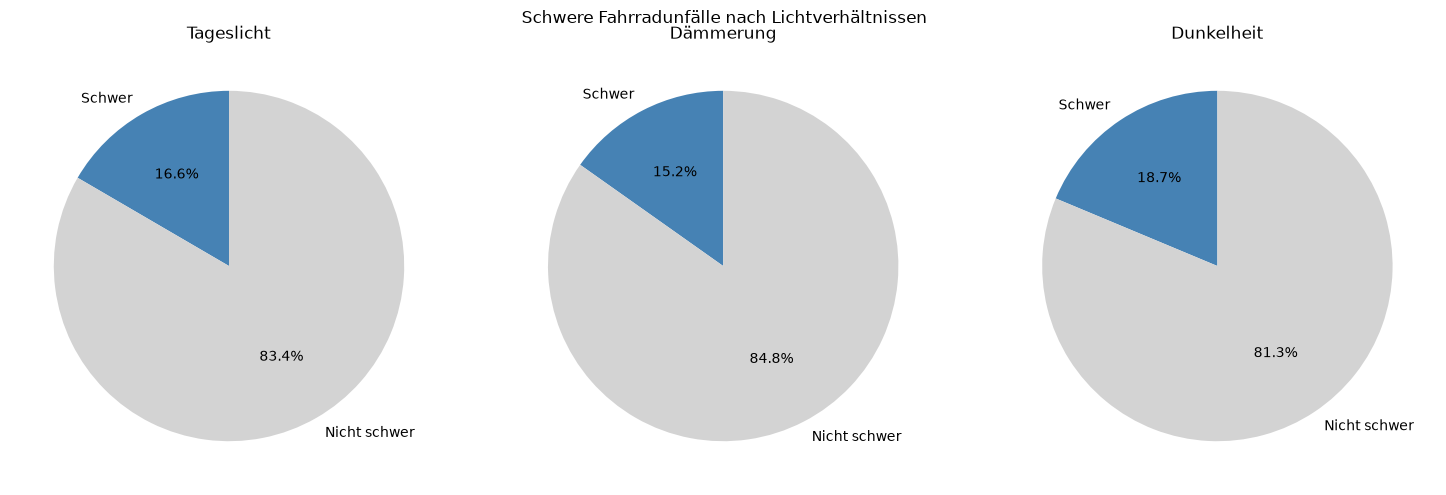

In [133]:
licht_namen = {
    0: "Tageslicht",
    1: "Dämmerung",
    2: "Dunkelheit"
}

nach_licht = schwere_nach_gruppe(df_rad, "ULICHTVERH").sort_index()
nach_licht.index = nach_licht.index.map(licht_namen)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (licht, gruppe) in zip(axes, nach_licht.iterrows()):
    schwer = gruppe["Anteil_schwer_%"]
    nicht_schwer = 100 - schwer

    ax.pie(
        [schwer, nicht_schwer],
        labels=["Schwer", "Nicht schwer"],
        autopct="%1.1f%%",
        startangle=90,
        colors=["steelblue", "lightgray"]
    )

    ax.set_title(licht)

plt.suptitle("Schwere Fahrradunfälle nach Lichtverhältnissen")
plt.tight_layout();

Der Anteil schwerer Fahrradunfälle unterscheidet sich je nach Lichtverhältnissen. Bei Dunkelheit lag er bei 18,7 %, bei Tageslicht bei 16,6 % und in der Dämmerung bei 15,2 %. Damit war der Anteil bei Dunkelheit um 2,1 Prozentpunkte höher als bei Tageslicht. Die Ergebnisse zeigen einen Zusammenhang zwischen den Lichtverhältnissen und der Unfallschwere, belegen jedoch keinen ursächlichen Einfluss der Dunkelheit.

4. Unfallbedingungen

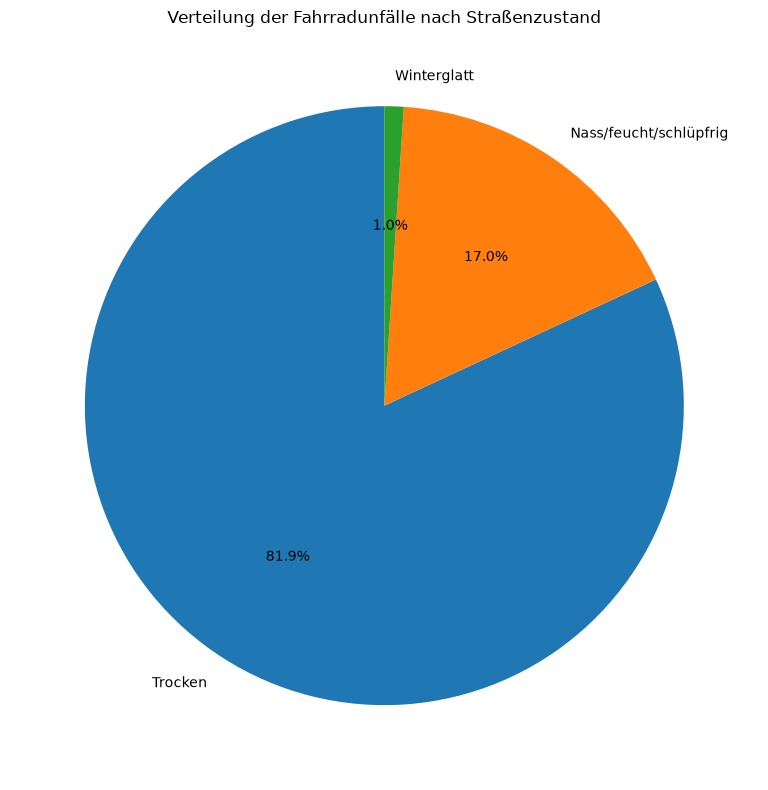

In [139]:
# 4.1 Fahrradunfälle nach Straßenzustand

zustand_namen = {
    0: "Trocken",
    1: "Nass/feucht/schlüpfrig",
    2: "Winterglatt"
}

unfaelle_strassenzustand = (
    df_rad["STRZUSTAND"]
    .value_counts()
    .rename(index=zustand_namen)
)

# Kreisdiagramm
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    unfaelle_strassenzustand.values,
    labels=unfaelle_strassenzustand.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Verteilung der Fahrradunfälle nach Straßenzustand")

plt.tight_layout();

Fazit
Die Auswertung zeigt, dass die meisten Fahrradunfälle bei trockenem Straßenzustand passierten. Insgesamt entfielen 81,9 % der erfassten Fahrradunfälle auf trockene Straßen. Bei nassen, feuchten oder schlüpfrigen Straßen ereigneten sich 17,0 % der Unfälle. Auf winterglatte Straßen entfielen 1,0 %.

Damit wurden die meisten Fahrradunfälle bei trockenem Straßenzustand registriert. Aus diesen Zahlen lässt sich jedoch nicht schließen, dass trockene Straßen gefährlicher sind, da auch die Häufigkeit der verschiedenen Straßenzustände im Straßenverkehr berücksichtigt werden müsste.
